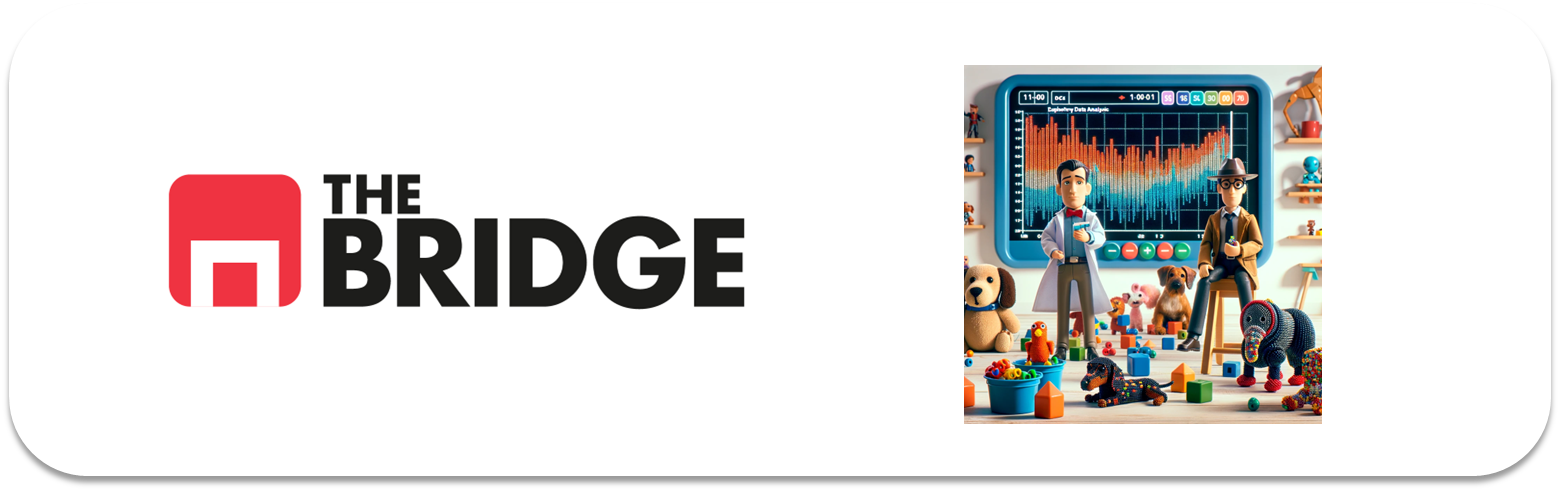

## Análisis de Datos (Multivariante): Cuando hay una categórica

A partir del análisis 2 a 2 de variables, el análisis tiende a complicarse o, más bien, a hacerse difícil de manejar. El número de combinaciones se dispara (a poco que tengas unas cuantas variables) y el consejo de probar todas las posibles se hace imposible de sostener.

Por eso, lo primero es lo primero:

1. Revisa las conclusiones y resultados de los análisis anteriores junto con tus preguntas del principio (si las tenías): cierra el conjunto de preguntas que no hayas contestado y quieras contestar.
2. Si puedes contestar alguna de esas preguntas atacando tus dataframes con análisis ad hoc (filtrar, agrupar...), contéstala.
3. Si todavía necesitas ver más de dos variables juntas, planifica: decide qué grupos de variables necesitas ver en conjunto para las preguntas del paso 1.
4. Y ahora sí: si una de esas variables es categórica (y quieres ver tres variables en conjunto), vale lo que te voy a contar.

Y como en todo el sprint, arranquemos con todo lo necesario:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from bootcampviztools import plot_categorical_numerical_relationship, plot_combined_graphs, \
    pinta_distribucion_categoricas, plot_grouped_boxplots, plot_categorical_relationship_fin, plot_grouped_histograms, \
        grafico_dispersion_con_correlacion

df_seguros = pd.read_csv("../data/Marketing-Customer-Analysis.csv")

### Tres variables: una categórica

Lo que sigue aplica a tres variables, si tienes más lo que tienes que hacer es generalizar el proceso (siempre que tengas al menos tantas variables categóricas como el total menos dos, si tienes 3 una, si quieres ver 4, dos y así).

Cuando tengas tres variables y una sea categórica lo que vamos a hacer es construir un análisis bivariante para cada una de las categorías de la variable categórica [¿Y si tengo dos variables categóricas, o las tres? Entonces usa la categórica más importante según tu criterio como variable directora: para cada uno de sus valores harás un análisis bivariante de las otras dos]. Veámoslo con dos ejemplos

### Seguros: Análisis response-renew_offer_type-education

Escojo esta combinación porque habíamos visto que había una variación significativa de las respuestas según la oferta y ahora quiero ver como se relaciona eso con el nivel de estudios


**#0 pinto todos los valores** iniciales

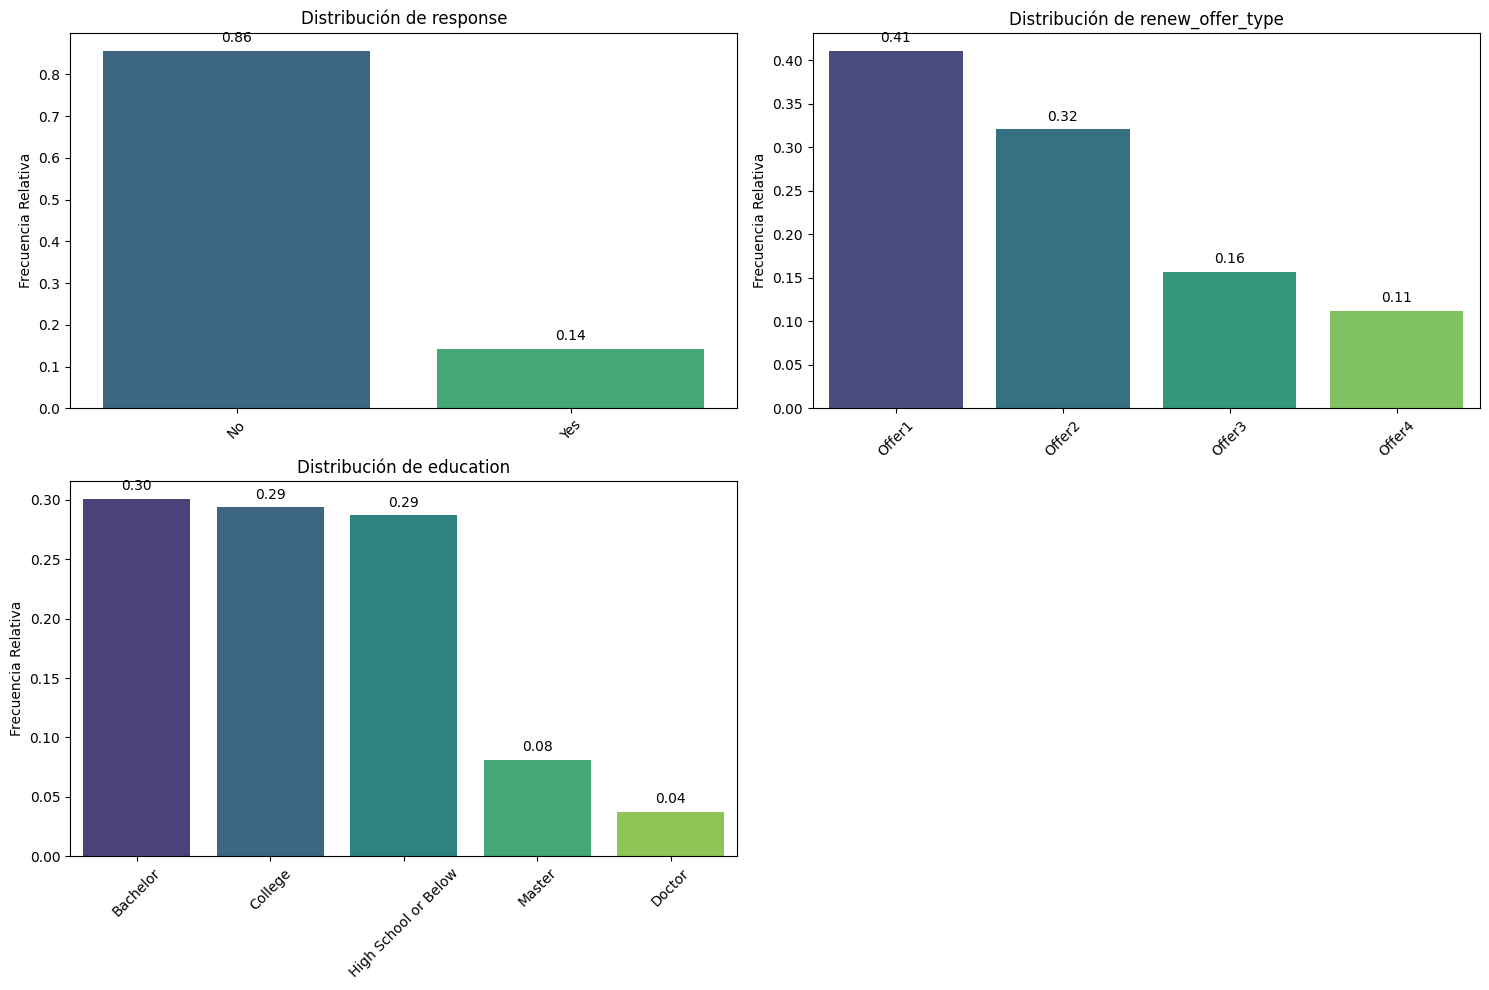

In [2]:
pinta_distribucion_categoricas(df_seguros,["response","renew_offer_type","education"], relativa= True, mostrar_valores= True)

**#1 Escojo variable directora** ya que tengo 3 categóricas y priorizo el resto

En este caso lo tengo claro, `response` es target, así que esa manda. Luego la siguiente que me interese, que era `renew_offer_type` y finalmente education

¿Por qué este orden? Porque en el bivariante vimos que la oferta tenía impacto en la respuesta. ¿Podría haber hecho un estudio bivariante de education con offer_type? Deberías haberlo hecho pero eso no garantiza el análisis con "response"

**#2 Muestro el bivariante de cada una con las otras dos**

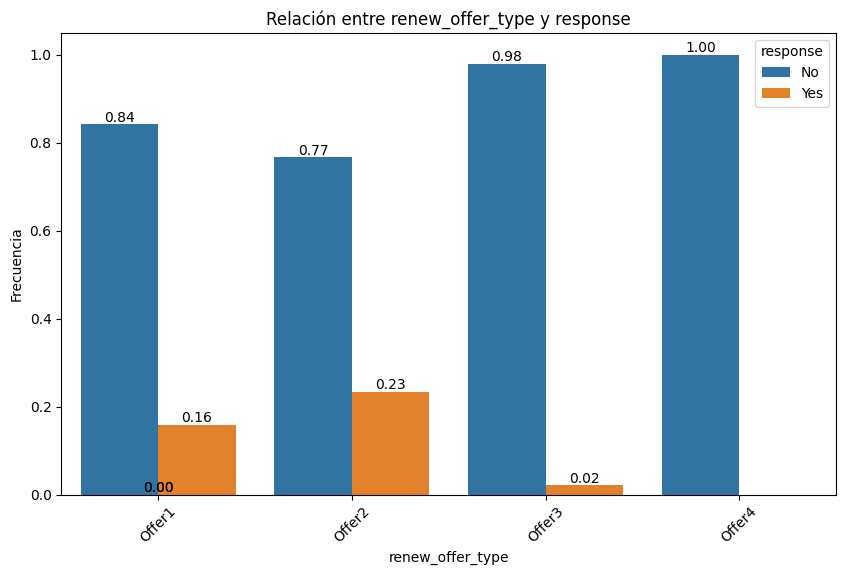

In [3]:
plot_categorical_relationship_fin(df_seguros,"renew_offer_type","response", relative_freq= True, show_values= True)

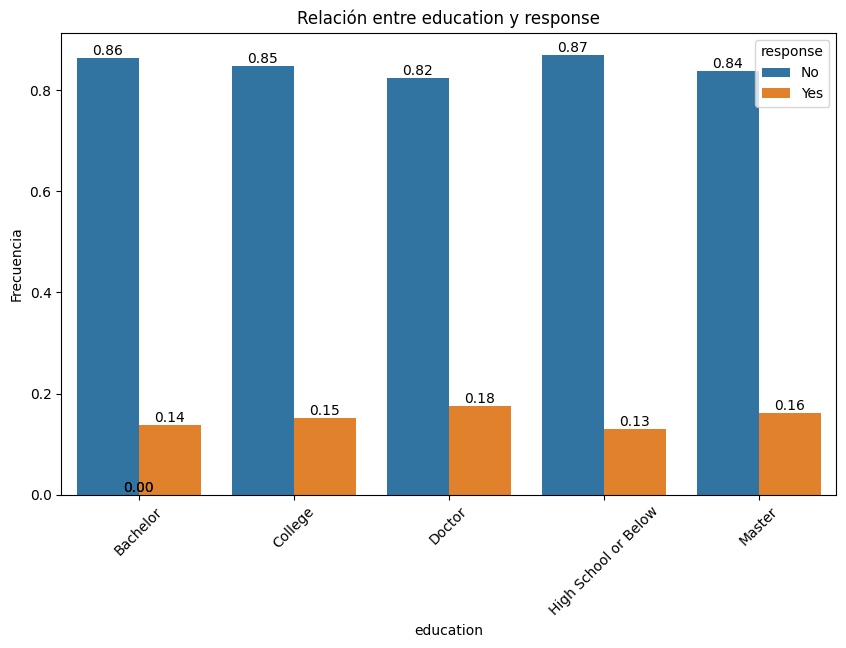

In [4]:
plot_categorical_relationship_fin(df_seguros,"education","response", relative_freq= True, show_values= True)

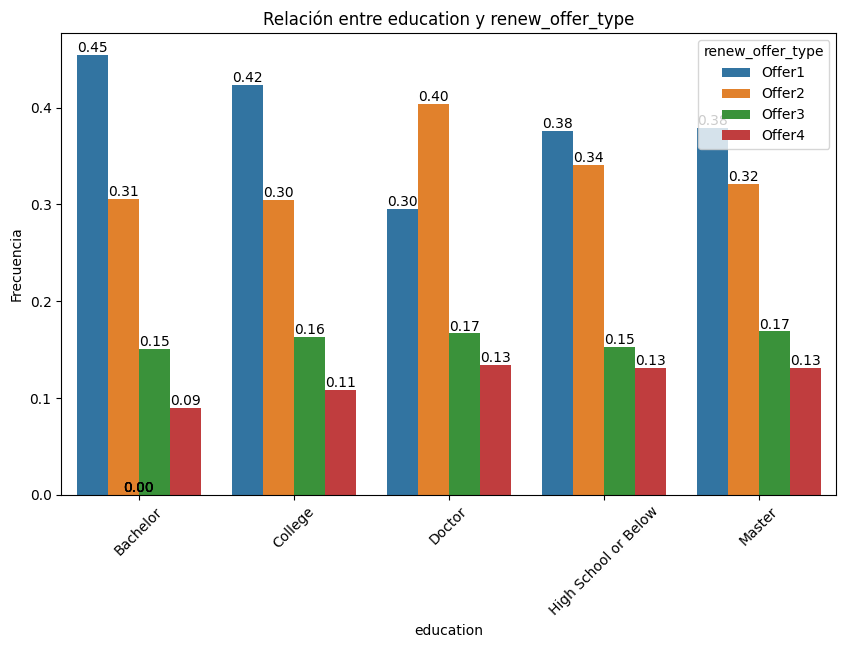

In [5]:
plot_categorical_relationship_fin(df_seguros,"education","renew_offer_type", relative_freq= True, show_values= True)

Ya podemos ir viendo algo, fijate que doctor tiene mejor ratio de respuesta, pero entre otras cosas le ofrecieron más la oferta_2

**#3 Divido mi dataset en tantos subdatasets (dataframes) como valores de mi categórica directora** y me quedo solo con las columnas de las otras dos variables

In [6]:
columnas = ["response","renew_offer_type","education"] 
col_directora = "response"
col_1 = [col for col in columnas if col != col_directora][0]
col_2 = [col for col in columnas if col != col_directora][1]
diccionario_multivariante = {}
for valor in df_seguros[col_directora].unique():
    diccionario_multivariante[valor] = df_seguros.loc[df_seguros[col_directora] == valor,[col_2,col_1]] # Ojo al orden quiero ver para cada oferta como es la distribución de educacion

**#4 Hago un análisis bivariante** para cada subdataset y comparo todo

Respuesta No:


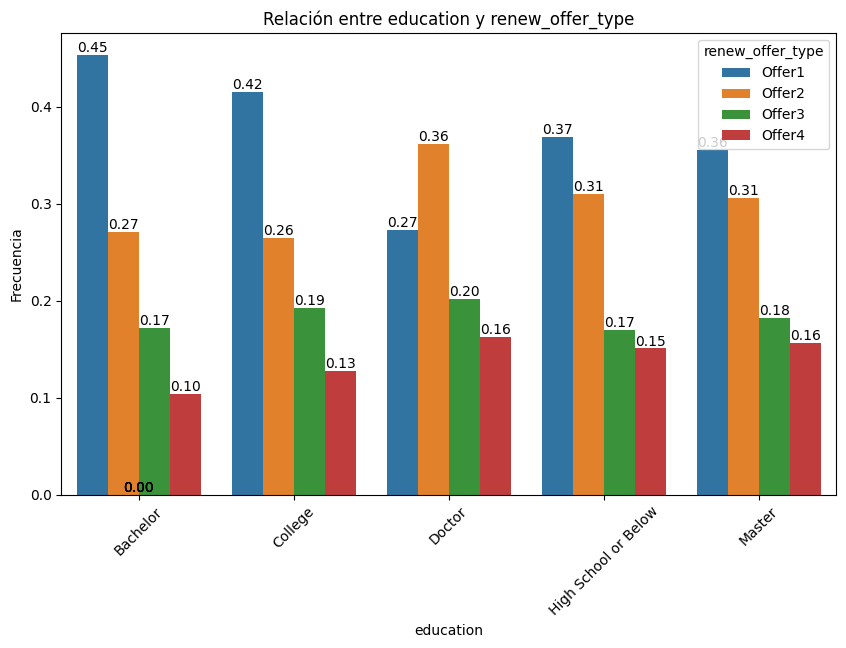

Respuesta Yes:


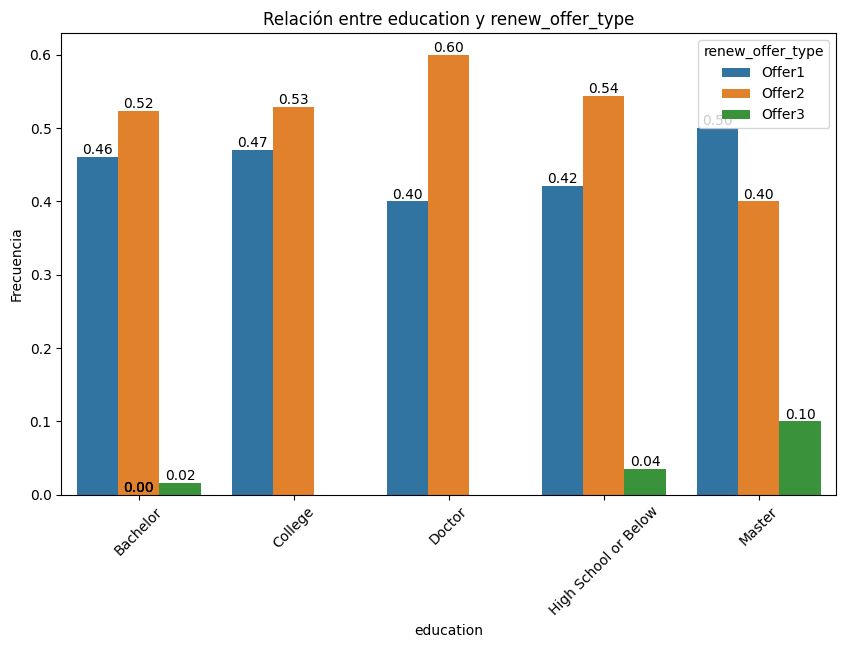

In [7]:
for valor,df_datos in diccionario_multivariante.items():
    print(f"Respuesta {valor}:")
    plot_categorical_relationship_fin(df_datos,col_2,col_1, relative_freq= True, show_values= True)

Y el análisis lo mezcla todo:
* De las bivariante sabemos que la oferta influye en la respuesta y también que no contestaron exactamente igual los doctores que el resto (tienen una tasa ligeramente superior de respuesta). Podría pensar que los doctores (o master) responden mejor.
* De observar la bivariante entre oferta y educación deberíamos sospechar que no tiene que ver con eso sino con el hecho de que los doctores recibieron más ofertas de tipo 2.
* El análisis a tres bandas, muestra varias cosas por un lado para todos los grupos de educación fue superior la respuesta a la oferta 2, salvo para Master y eso habría que analizarlo mejor (ya sabes algo que destaca), pero para los doctores también fue aparentemente mejor. Además en Master es donde funciona la oferta3. Estos resultados son bastante interesantes (pero poniendolos en el contexto de que tanto Doctores como Masters son los segmento más pequeños con diferencia). 
* En definitiva la oferta 2 es claramente superior, aparentemente es más efectiva en Doctores y menos efectiva en Master donde además la oferta 3 es más efectiva.

### Seguros: Análisis número de pólizas - prima mensual - CLV

Segundo ejemplo, ahora con **una categórica y dos numéricas**. En el bivariante vimos que la prima mensual y el CLV tienen una correlación moderada (≈ 0,40). ¿Es igual para todos los clientes?

Usamos como directora el número de pólizas contratadas. Como tiene 9 valores, la agrupamos en tres: 1, 2 y 3 o más.

In [8]:
df_seguros["polizas"] = pd.cut(df_seguros["number_of_policies"], bins=[0, 1, 2, 9], labels=["1", "2", "3 o más"])
df_seguros["polizas"].value_counts()

polizas
3 o más    3589
1          3251
2          2294
Name: count, dtype: int64

**#1 Bivariante global** de las dos numéricas, como referencia:

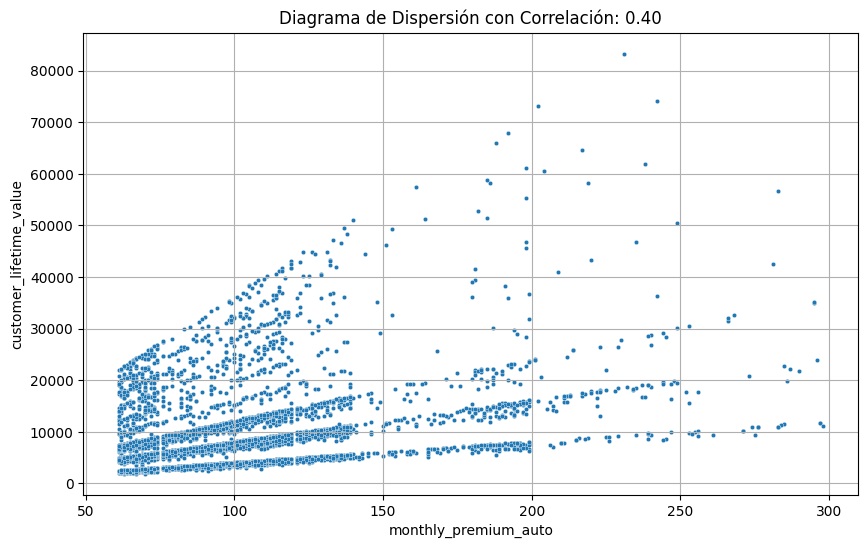

In [9]:
grafico_dispersion_con_correlacion(df_seguros, "monthly_premium_auto", "customer_lifetime_value", tamano_puntos=10, mostrar_correlacion=True)

**#2 Divido el dataset** según la directora:

In [10]:
col_directora = "polizas"
col_1 = "monthly_premium_auto"
col_2 = "customer_lifetime_value"
diccionario_multivariante = {}
for valor in df_seguros[col_directora].unique():
    diccionario_multivariante[valor] = df_seguros.loc[df_seguros[col_directora] == valor, [col_1, col_2]]

**#3 Hago un análisis bivariante** para cada subdataset y comparo:

Pólizas: 1


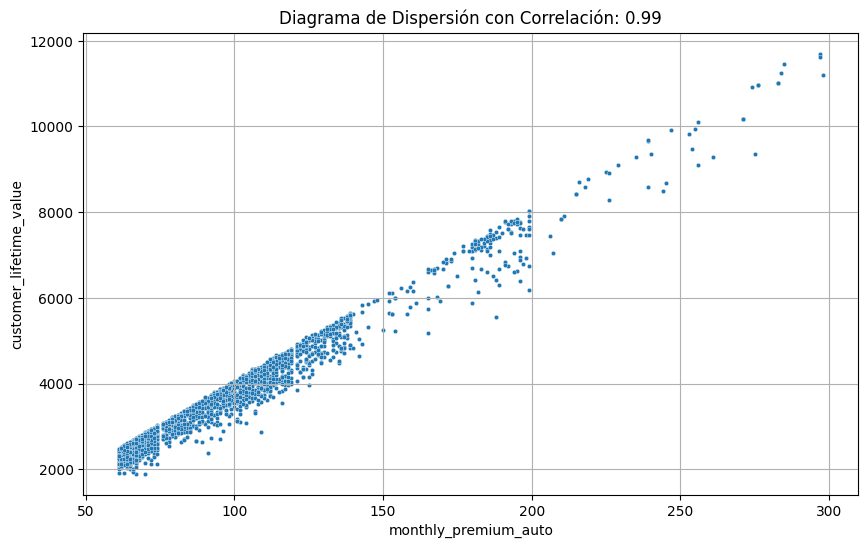

Pólizas: 2


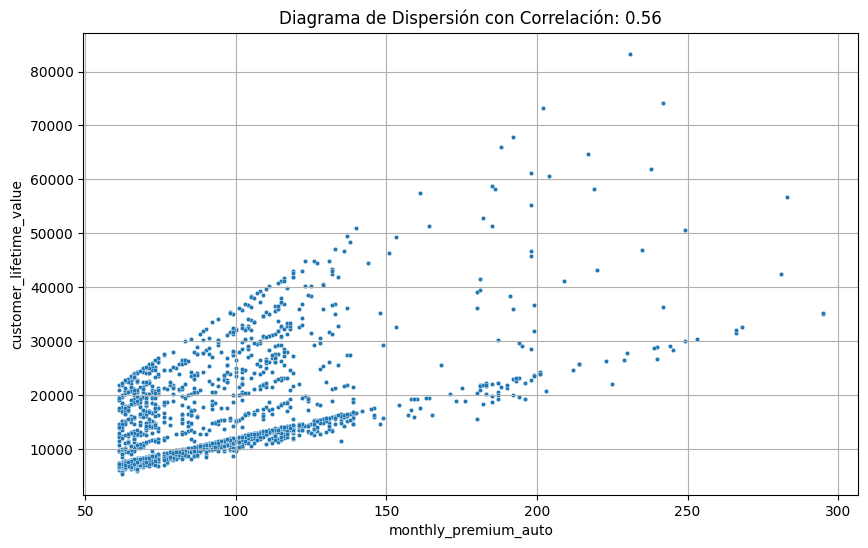

Pólizas: 3 o más


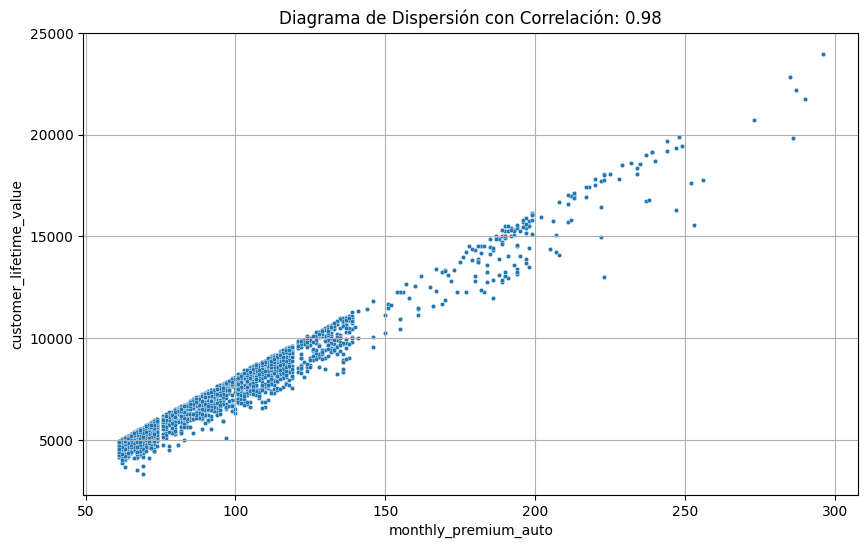

In [11]:
for valor in ["1", "2", "3 o más"]:
    print(f"Pólizas: {valor}")
    grafico_dispersion_con_correlacion(diccionario_multivariante[valor], col_1, col_2, tamano_puntos=10, mostrar_correlacion=True)

Este resultado es de los que justifican un análisis multivariante:
* Dentro de los clientes con **1 póliza** y con **3 o más**, la relación entre prima y CLV es **casi perfectamente lineal** (correlación ≈ 0,99 y ≈ 0,98).
* Los clientes con **2 pólizas** se comportan distinto: CLV mucho más alto y una relación mucho más débil.
* Al mezclar los tres grupos, la correlación global se queda en 0,40: **el análisis bivariante escondía la estructura real**.

Lección: una tercera variable puede esconder (o crear) una relación entre otras dos. Y una pista para seguir investigando: los clientes con 2 pólizas son los que concentran los CLV más altos (lo comprobaremos en Data Cleaning, al tratar los outliers).